In [ ]:
import pandas as pd
df = pd.read_csv(r'C:\Users\siddi\OneDrive\Desktop\College\TE\SEM 6\DS Lab\reddit_dead_internet_analysis_2026.csv')

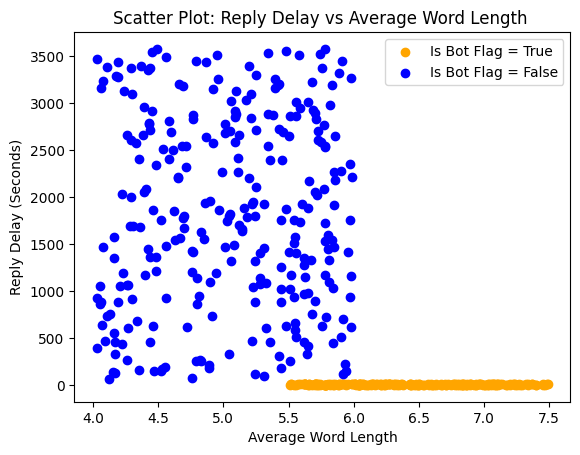

In [ ]:
# Scatter plot between 'reply_delay_seconds' and 'avg_word_length'
# is_bot_flag is true will be orange in color while false is blue in color
import matplotlib.pyplot as plt
plt.scatter(df[df['is_bot_flag']==True]['avg_word_length'], df[df['is_bot_flag']==True]['reply_delay_seconds'], c='orange', label='Is Bot Flag = True')
plt.scatter(df[df['is_bot_flag']==False]['avg_word_length'], df[df['is_bot_flag']==False]['reply_delay_seconds'], c='blue', label='Is Bot Flag = False')
plt.xlabel('Average Word Length')
plt.ylabel('Reply Delay (Seconds)')
plt.title('Scatter Plot: Reply Delay vs Average Word Length ')
plt.legend()

plt.show()

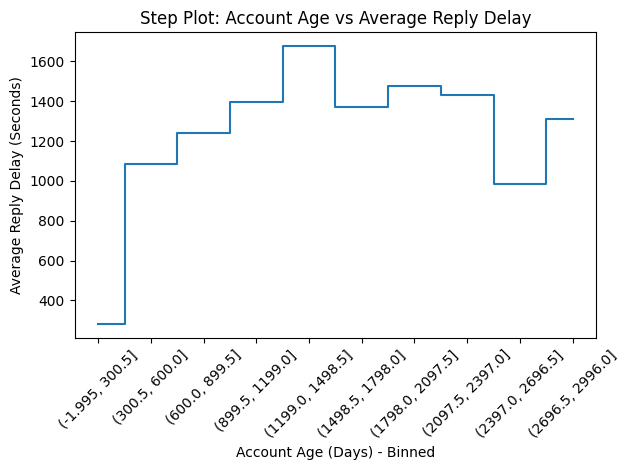

In [ ]:
# Step plot
# Columns:
# account_age_days (x, binned)
# bot_probability (or) reply_delay_seconds (y)
# Filters:
# Bin account_age_days into fixed intervals
# Aggregate using mean or median
# Remove extreme outliers in reply_delay_seconds
df['account_age_bins'] = pd.cut(df['account_age_days'], bins=10)
agg_data = df.groupby('account_age_bins')['reply_delay_seconds'].mean().reset_index()
plt.step(agg_data['account_age_bins'].astype(str), agg_data['reply_delay_seconds'], where='mid')
plt.xlabel('Account Age (Days) - Binned')
plt.ylabel('Average Reply Delay (Seconds)')
plt.title('Step Plot: Account Age vs Average Reply Delay')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

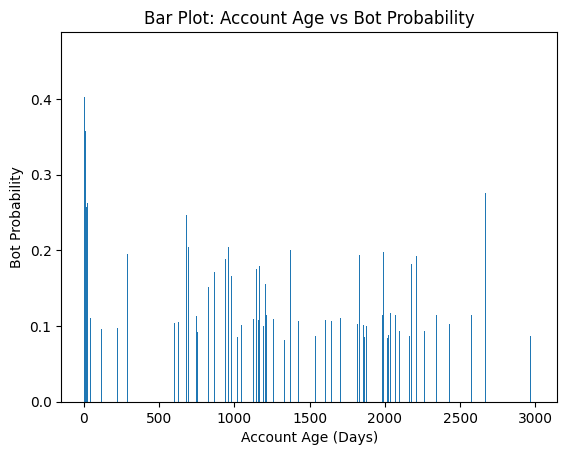

In [ ]:
# Bar plot between 'account_age_days' and 'bot_probability'
df_sorted = df.sort_values(by='account_age_days')
plt.bar(df_sorted['account_age_days'], df_sorted['bot_probability'])
plt.xlabel('Account Age (Days)')
plt.ylabel('Bot Probability')
plt.title('Bar Plot: Account Age vs Bot Probability')
plt.show()

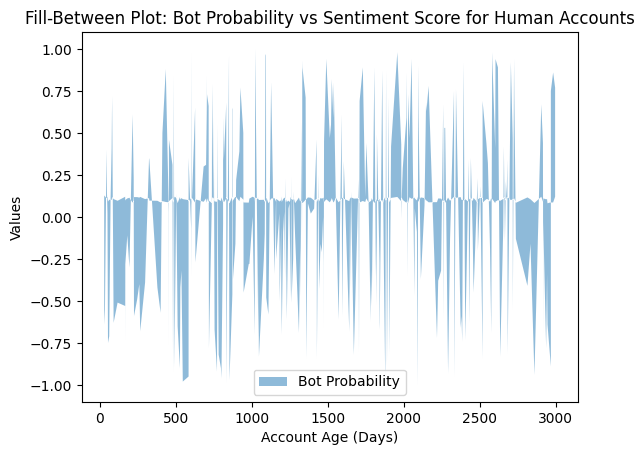

In [ ]:
# Fill-between plot
# Columns:
# account_age_days (x)
# bot_probability (y1)
# sentiment_score (or) avg_word_length (y2)
# Filters:
# is_bot_flag == False (focus on human behavior)
# Sort by account_age_days
# Optionally bin account_age_days (e.g., 0–365, 366–1000, …) and take mean values
df_human = df[df['is_bot_flag'] == False]
df_human_sorted = df_human.sort_values(by='account_age_days')
plt.fill_between(df_human_sorted['account_age_days'], df_human_sorted['bot_probability'], df_human_sorted['sentiment_score'], alpha=0.5)
plt.xlabel('Account Age (Days)')
plt.ylabel('Values')
plt.title('Fill-Between Plot: Bot Probability vs Sentiment Score for Human Accounts')
plt.legend(['Bot Probability', 'Sentiment Score'])
plt.show()

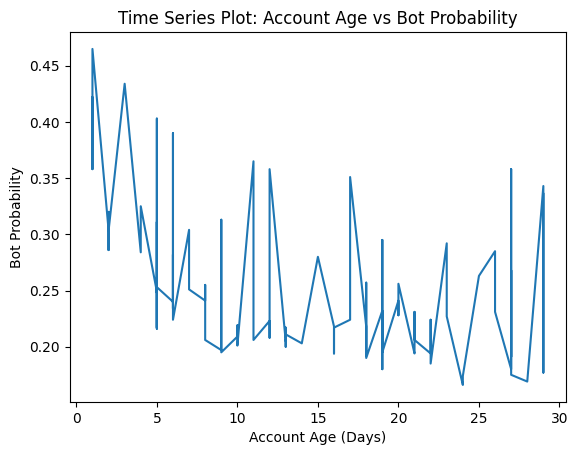

In [ ]:
# Time series plot
# Columns:
# account_age_days (x)
# bot_probability (y)
# Filters:
# Sort by account_age_days
# Optionally bin account_age_days (e.g., 0–365, 366–1000, …) and take mean values
# is_bot_flag is true will be orange in color while false is blue in color
df_sorted = df.sort_values(by='account_age_days').head(100)  # Limit to first 100 for better visualization
plt.plot(df_sorted['account_age_days'], df_sorted['bot_probability'], label='All Accounts')
plt.xlabel('Account Age (Days)')
plt.ylabel('Bot Probability')
plt.title('Time Series Plot: Account Age vs Bot Probability')   
plt.legend()
plt.show()

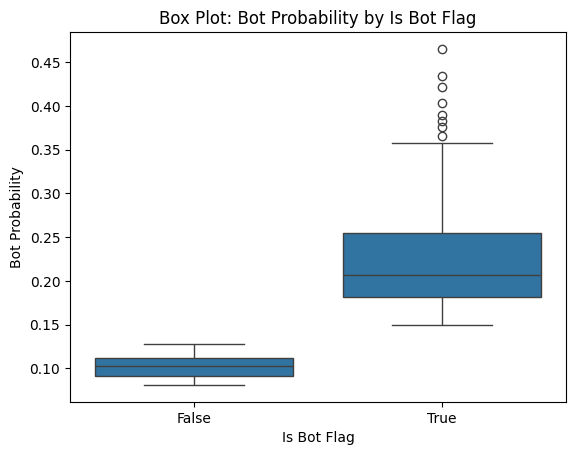

In [ ]:
# Box plot between 'bot_probability' and 'is_bot_flag'
import seaborn as sns
sns.boxplot(x='is_bot_flag', y='bot_probability', data=df)
plt.xlabel('Is Bot Flag')
plt.ylabel('Bot Probability')
plt.title('Box Plot: Bot Probability by Is Bot Flag')
plt.show()

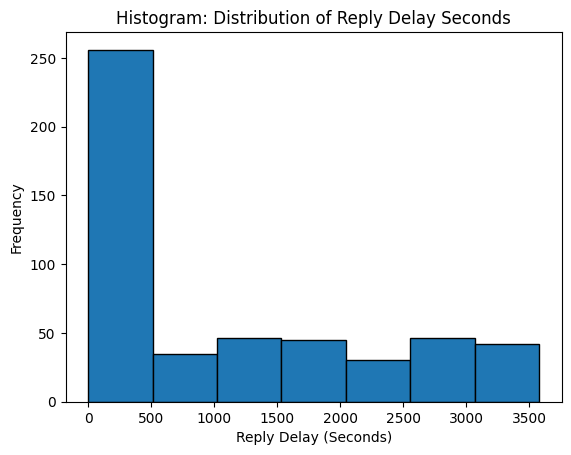

In [ ]:
# Histogram of 'reply_delay_seconds'
# Bins of size 500
plt.hist(df['reply_delay_seconds'], bins=7, edgecolor='black')
plt.xlabel('Reply Delay (Seconds)')
plt.ylabel('Frequency')
plt.title('Histogram: Distribution of Reply Delay Seconds')
plt.show()